In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, f_classif


from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance


import joblib

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving soil_fertility_classification_1000.csv to soil_fertility_classification_1000.csv


In [3]:
df = pd.read_csv(
    "soil_fertility_classification_1000.csv"
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1000, 20)


,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score,Fertility_Class
0,SFC-0001,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Lucknow,Alluvial,Cotton,6.91,0.150,12.08,169.90,32.32,54.05,15.46,1.34,1.13,16.65,7.20,1.00,47.15,Medium Fertility
1,SFC-0002,Indian laboratory soil dataset calibrated exte...,Maharashtra,Nashik,Red,Cotton,6.61,0.424,10.85,170.47,31.70,126.62,11.17,0.87,1.39,15.67,6.15,1.36,46.47,Medium Fertility
2,SFC-0003,Indian laboratory soil dataset calibrated exte...,Karnataka,Mysuru,Loamy,Pulses,7.52,0.596,5.51,130.75,32.14,381.20,10.98,0.51,0.83,21.16,5.31,0.69,39.27,Low Fertility
3,SFC-0004,Indian laboratory soil dataset calibrated exte...,Punjab,Ludhiana,Clay Loam,Rice,7.03,0.257,9.48,202.66,49.68,77.23,20.79,0.76,1.60,38.51,9.07,0.60,59.38,Medium Fertility
4,SFC-0005,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Bareilly,Loamy,Vegetables,7.17,0.282,15.65,189.12,24.58,213.50,17.32,1.35,0.47,25.92,17.15,1.20,61.00,Medium Fertility


In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData Types:")
display(df.dtypes)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Sample_ID                     1000 non-null   object 
 1   Source_Calibration            1000 non-null   object 
 2   State                         1000 non-null   object 
 3   District                      1000 non-null   object 
 4   Soil_Type                     1000 non-null   object 
 5   Crop                          1000 non-null   object 
 6   pH                            1000 non-null   float64
 7   Electrical_Conductivity_dS_m  1000 non-null   float64
 8   Organic_Carbon_g_kg           1000 non-null   float64
 9   Available_N_kg_ha             1000 non-null   float64
 10  Available_P_kg_ha             1000 non-null   float64
 11  Available_K_kg_ha             1000 non-null   float64
 12  Sulphur_mg_kg                 1000 non-nul

,0
Sample_ID,object
Source_Calibration,object
State,object
District,object
Soil_Type,object
Crop,object
pH,float64
Electrical_Conductivity_dS_m,float64
Organic_Carbon_g_kg,float64
Available_N_kg_ha,float64


In [5]:
print("Statistical Summary:")

display(df.describe())

print("\nCategorical Summary:")

display(df.describe(include="object"))

Statistical Summary:


,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,6.972970,0.509072,7.738160,177.409290,43.025280,182.106470,13.15811,0.877450,0.763730,21.041950,8.921410,0.763090,47.787490
std,0.538233,0.298188,4.391373,43.067258,28.871288,85.083336,6.43995,0.413889,0.355486,12.588565,5.058256,0.362168,15.367468
min,5.650000,0.060000,1.510000,81.540000,4.710000,48.600000,2.31000,0.170000,0.200000,2.800000,1.420000,0.150000,11.290000
25%,6.610000,0.295000,4.705000,147.370000,22.447500,115.827500,8.50750,0.580000,0.500000,12.187500,5.492500,0.510000,37.190000
50%,6.970000,0.449500,6.590000,177.215000,36.010000,180.125000,11.74500,0.780000,0.690000,18.040000,7.750000,0.680000,47.755000
75%,7.340000,0.643250,9.792500,205.752500,53.897500,242.390000,16.11500,1.090000,0.930000,26.682500,11.132500,0.950000,58.195000
max,8.120000,1.900000,24.750000,305.930000,136.600000,381.200000,40.00000,3.150000,3.030000,80.000000,39.790000,2.720000,94.190000



Categorical Summary:


,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,Fertility_Class
count,1000,1000,1000,1000,1000,1000,1000
unique,1000,2,8,18,7,8,3
top,SFC-1000,Indian laboratory soil dataset calibrated exte...,Uttar Pradesh,Meerut,Alluvial,Groundnut,Medium Fertility
freq,1,509,310,109,304,155,596


In [6]:
print("Missing Values in Each Column:")

missing_values = df.isnull().sum()

print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values in Each Column:
Sample_ID                       0
Source_Calibration              0
State                           0
District                        0
Soil_Type                       0
Crop                            0
pH                              0
Electrical_Conductivity_dS_m    0
Organic_Carbon_g_kg             0
Available_N_kg_ha               0
Available_P_kg_ha               0
Available_K_kg_ha               0
Sulphur_mg_kg                   0
Zinc_mg_kg                      0
Boron_mg_kg                     0
Iron_mg_kg                      0
Manganese_mg_kg                 0
Copper_mg_kg                    0
Fertility_Score                 0
Fertility_Class                 0
dtype: int64

Total Missing Values:
0


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Sample IDs:",
    df["Sample_ID"].duplicated().sum()
)


df = df.drop_duplicates().copy()

print("Dataset Shape After Cleaning:", df.shape)

Duplicate Rows: 0
Duplicate Sample IDs: 0
Dataset Shape After Cleaning: (1000, 20)


In [8]:

invalid_ph = df[
    (df["pH"] < 0) |
    (df["pH"] > 14)
]

print("Invalid pH Values:", len(invalid_ph))


chemical_columns = [
    "Electrical_Conductivity_dS_m",
    "Organic_Carbon_g_kg",
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha",
    "Sulphur_mg_kg",
    "Zinc_mg_kg",
    "Boron_mg_kg",
    "Iron_mg_kg",
    "Manganese_mg_kg",
    "Copper_mg_kg"
]

for col in chemical_columns:
    negative_count = (df[col] < 0).sum()

    print(col, ":", negative_count, "negative values")

Invalid pH Values: 0
Electrical_Conductivity_dS_m : 0 negative values
Organic_Carbon_g_kg : 0 negative values
Available_N_kg_ha : 0 negative values
Available_P_kg_ha : 0 negative values
Available_K_kg_ha : 0 negative values
Sulphur_mg_kg : 0 negative values
Zinc_mg_kg : 0 negative values
Boron_mg_kg : 0 negative values
Iron_mg_kg : 0 negative values
Manganese_mg_kg : 0 negative values
Copper_mg_kg : 0 negative values


In [9]:
# Convert impossible measurements to missing values
df.loc[
    ~df["pH"].between(0, 14),
    "pH"
] = np.nan

for col in chemical_columns:
    df.loc[df[col] < 0, col] = np.nan

# Standardize categorical text
categorical_columns = [
    "State",
    "District",
    "Soil_Type",
    "Crop",
    "Fertility_Class"
]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()

# Remove records without target labels
df = df.dropna(subset=["Fertility_Class"])

# Validate target categories
valid_classes = [
    "Low Fertility",
    "Medium Fertility",
    "High Fertility"
]

unexpected = set(df["Fertility_Class"]) - set(valid_classes)

if unexpected:
    raise ValueError(
        f"Unexpected target categories: {unexpected}"
    )

print("Data cleaning completed!")
print("Final Shape:", df.shape)

Data cleaning completed!
Final Shape: (1000, 20)


In [10]:
print("Fertility Class Distribution:")

class_counts = df["Fertility_Class"].value_counts()

print(class_counts)

print("\nPercentage Distribution:")

print(
    df["Fertility_Class"]
    .value_counts(normalize=True) * 100
)

Fertility Class Distribution:
Fertility_Class
Medium Fertility    596
Low Fertility       319
High Fertility       85
Name: count, dtype: Int64

Percentage Distribution:
Fertility_Class
Medium Fertility    59.6
Low Fertility       31.9
High Fertility       8.5
Name: proportion, dtype: Float64


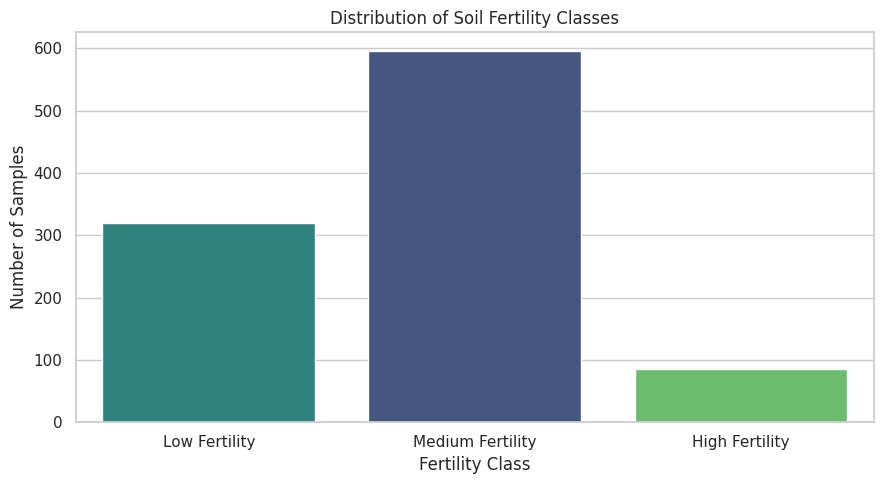

In [11]:
plt.figure(figsize=(9, 5))

order = [
    "Low Fertility",
    "Medium Fertility",
    "High Fertility"
]

sns.countplot(
    data=df,
    x="Fertility_Class",
    order=order,
    hue="Fertility_Class",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Soil Fertility Classes")
plt.xlabel("Fertility Class")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

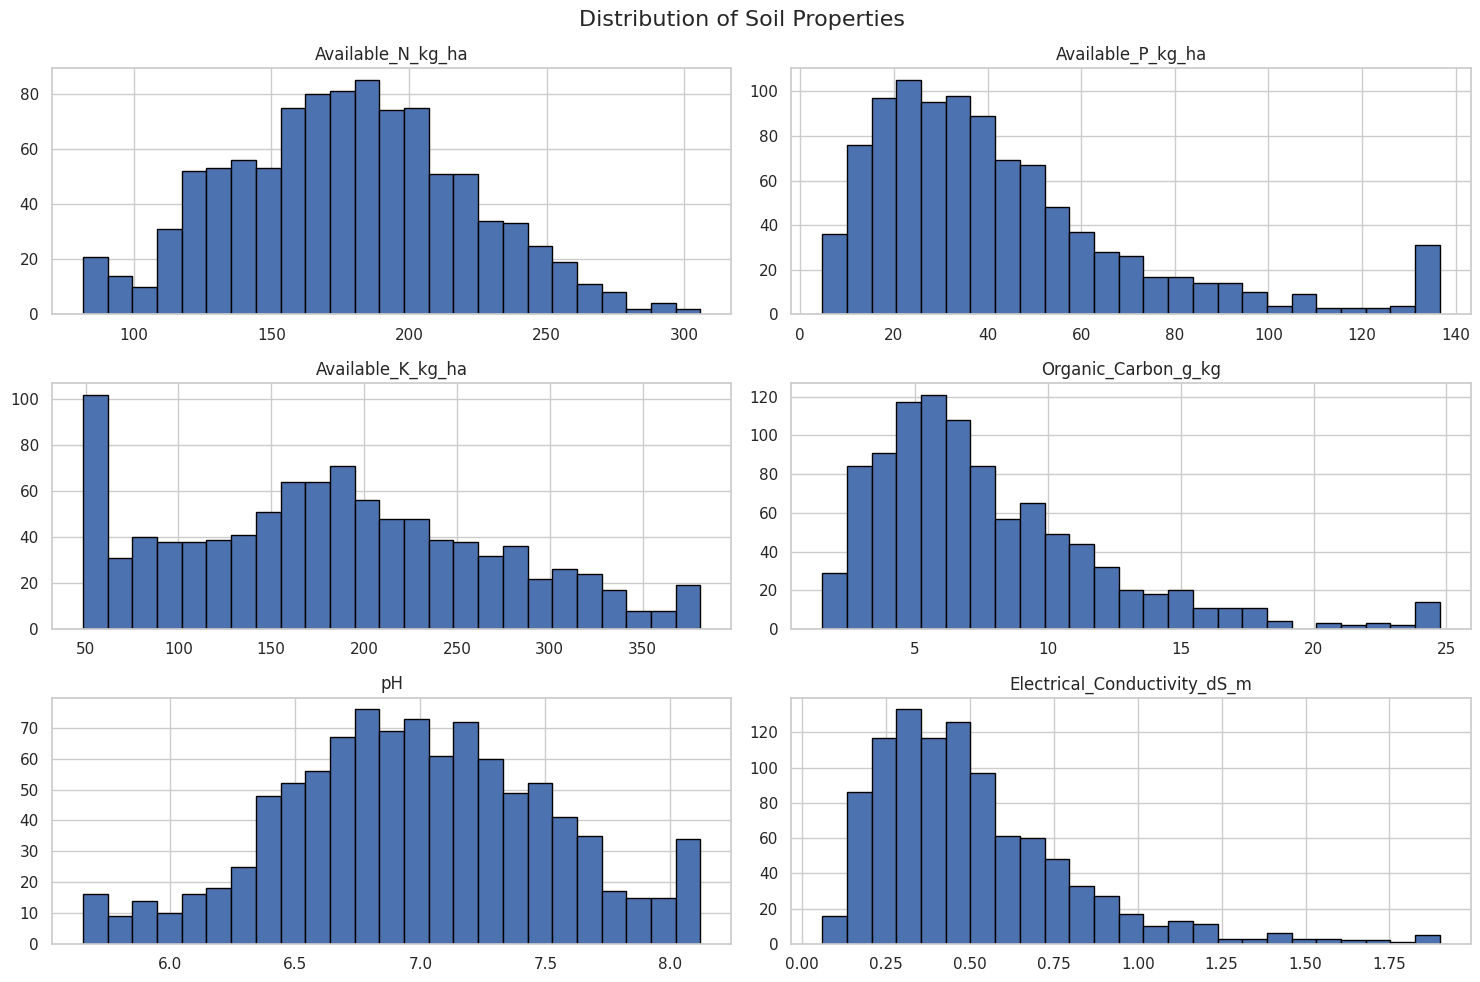

In [12]:
nutrient_columns = [
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha",
    "Organic_Carbon_g_kg",
    "pH",
    "Electrical_Conductivity_dS_m"
]

df[nutrient_columns].hist(
    bins=25,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Soil Properties",
    fontsize=16
)

plt.tight_layout()
plt.show()

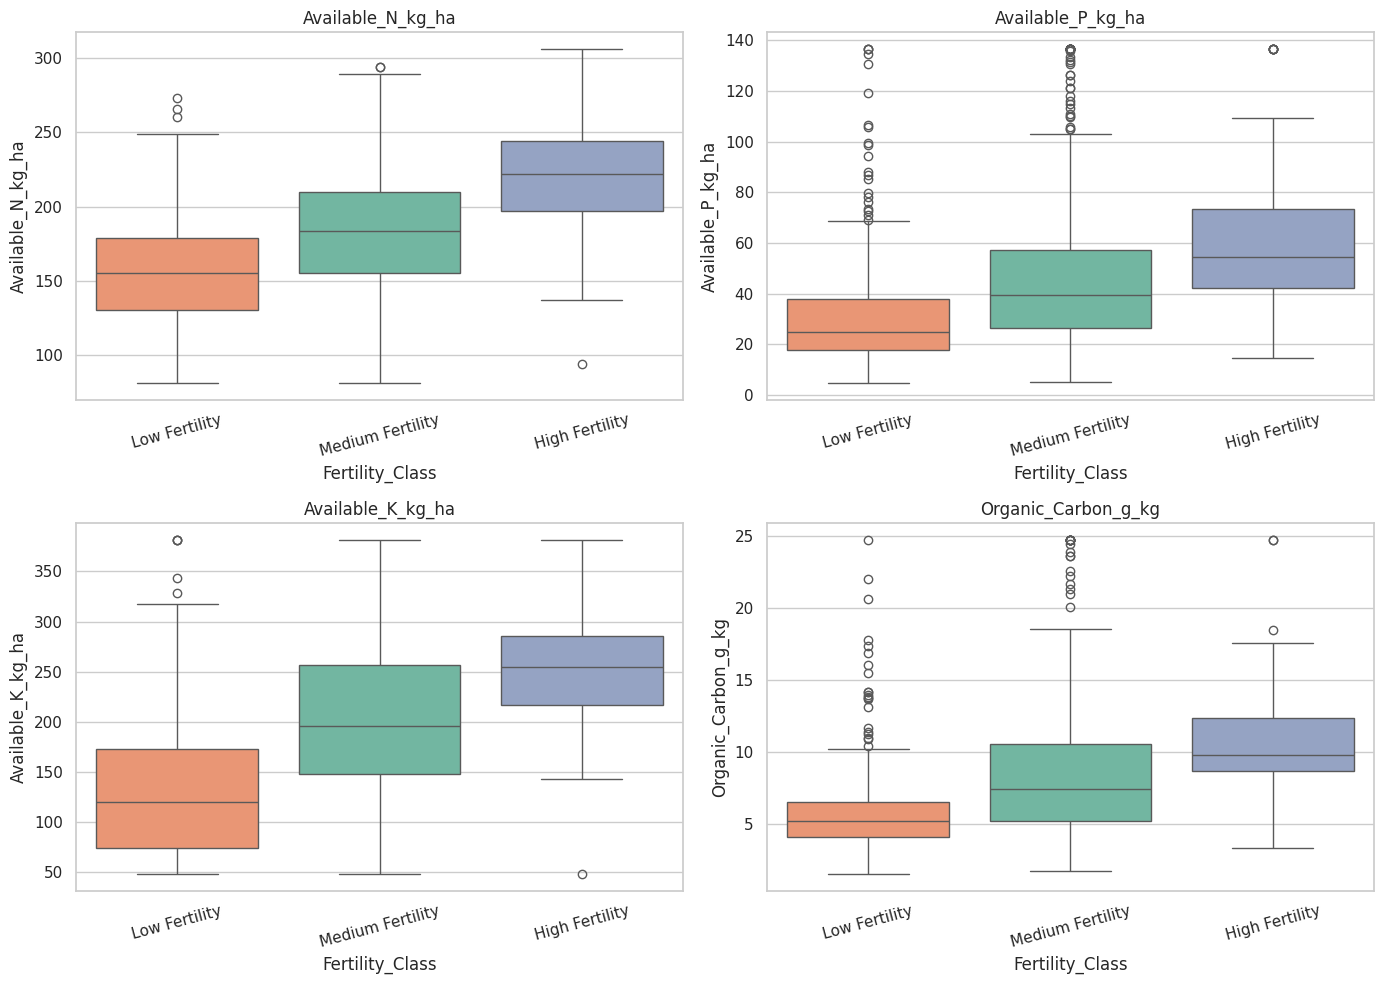

In [13]:
features_to_plot = [
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha",
    "Organic_Carbon_g_kg"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, feature in zip(axes.flatten(), features_to_plot):

    sns.boxplot(
        data=df,
        x="Fertility_Class",
        y=feature,
        order=order,
        hue="Fertility_Class",
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

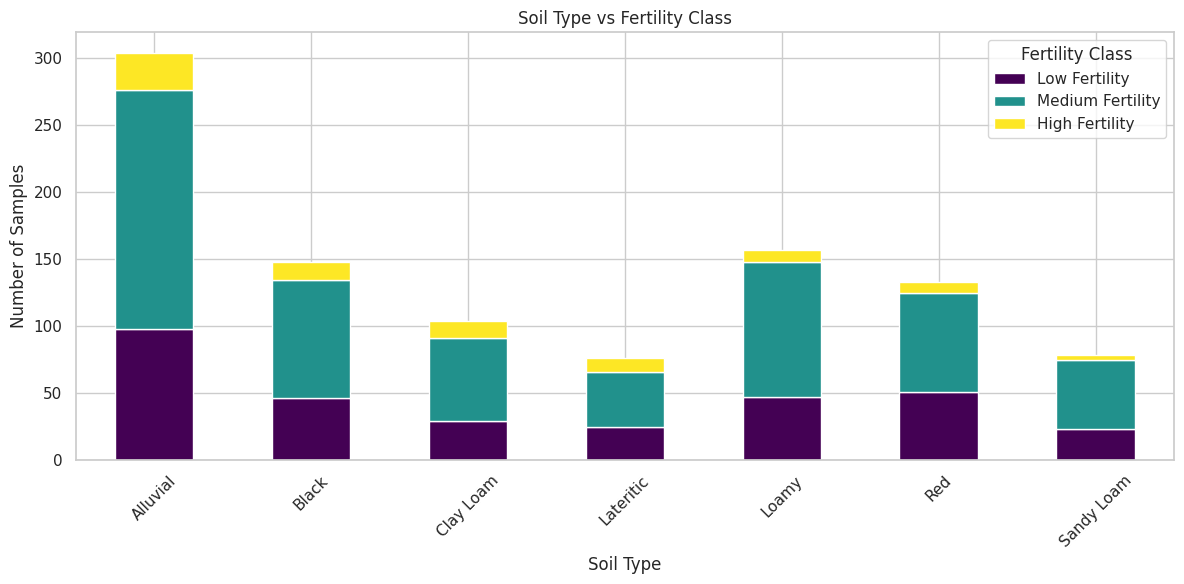

In [14]:
soil_fertility = pd.crosstab(
    df["Soil_Type"],
    df["Fertility_Class"]
)

soil_fertility = soil_fertility.reindex(
    columns=order,
    fill_value=0
)

soil_fertility.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Soil Type vs Fertility Class")
plt.xlabel("Soil Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.legend(title="Fertility Class")

plt.tight_layout()
plt.show()

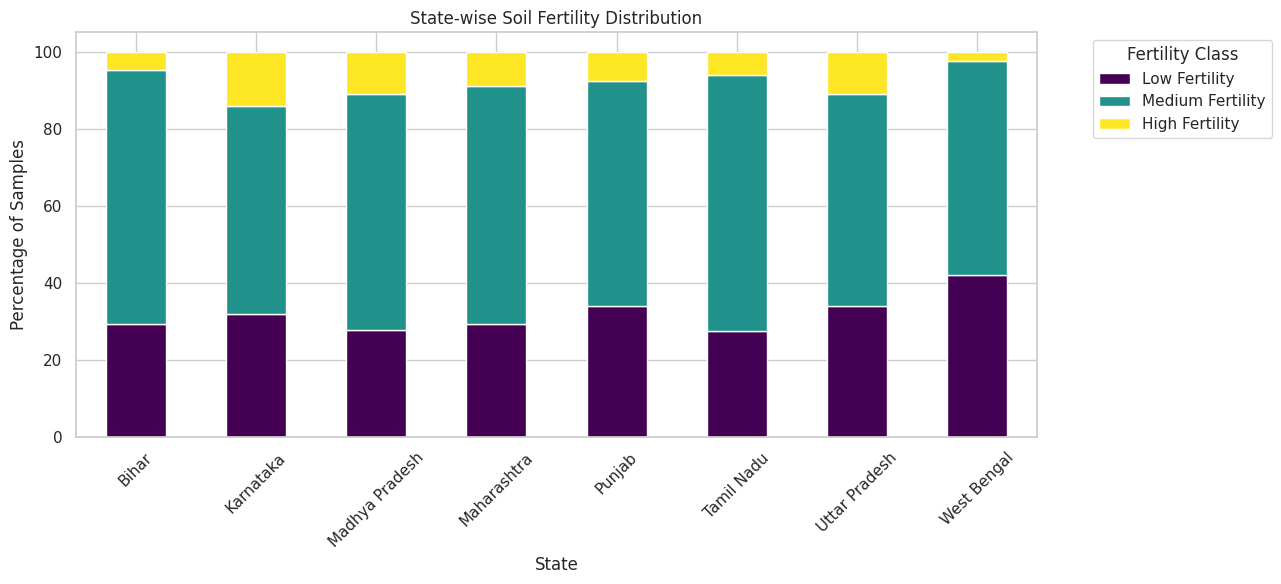

In [15]:
state_fertility = pd.crosstab(
    df["State"],
    df["Fertility_Class"],
    normalize="index"
) * 100

state_fertility = state_fertility.reindex(
    columns=order,
    fill_value=0
)

state_fertility.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    colormap="viridis"
)

plt.title("State-wise Soil Fertility Distribution")
plt.xlabel("State")
plt.ylabel("Percentage of Samples")

plt.xticks(rotation=45)
plt.legend(
    title="Fertility Class",
    bbox_to_anchor=(1.05, 1)
)

plt.tight_layout()
plt.show()

In [16]:
numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score
pH,1.00,-0.02,-0.00,0.03,0.04,-0.03,-0.00,-0.02,-0.01,0.01,0.00,0.01,-0.02
Electrical_Conductivity_dS_m,-0.02,1.00,-0.04,0.03,-0.02,-0.02,-0.01,-0.01,-0.02,0.06,0.03,-0.02,-0.07
Organic_Carbon_g_kg,-0.00,-0.04,1.00,-0.01,-0.02,-0.06,-0.00,-0.03,-0.03,-0.00,-0.01,-0.01,0.38
Available_N_kg_ha,0.03,0.03,-0.01,1.00,-0.04,0.03,-0.03,-0.04,0.02,-0.02,-0.03,-0.01,0.47
Available_P_kg_ha,0.04,-0.02,-0.02,-0.04,1.00,0.03,-0.02,0.01,0.06,0.02,-0.06,-0.04,0.35
Available_K_kg_ha,-0.03,-0.02,-0.06,0.03,0.03,1.00,0.06,-0.04,0.02,-0.03,-0.03,0.04,0.53
Sulphur_mg_kg,-0.00,-0.01,-0.00,-0.03,-0.02,0.06,1.00,0.03,0.00,0.06,-0.04,0.01,0.01
Zinc_mg_kg,-0.02,-0.01,-0.03,-0.04,0.01,-0.04,0.03,1.00,0.02,0.03,-0.02,-0.02,-0.08
Boron_mg_kg,-0.01,-0.02,-0.03,0.02,0.06,0.02,0.00,0.02,1.00,0.02,-0.06,0.05,0.02
Iron_mg_kg,0.01,0.06,-0.00,-0.02,0.02,-0.03,0.06,0.03,0.02,1.00,-0.00,0.01,-0.02


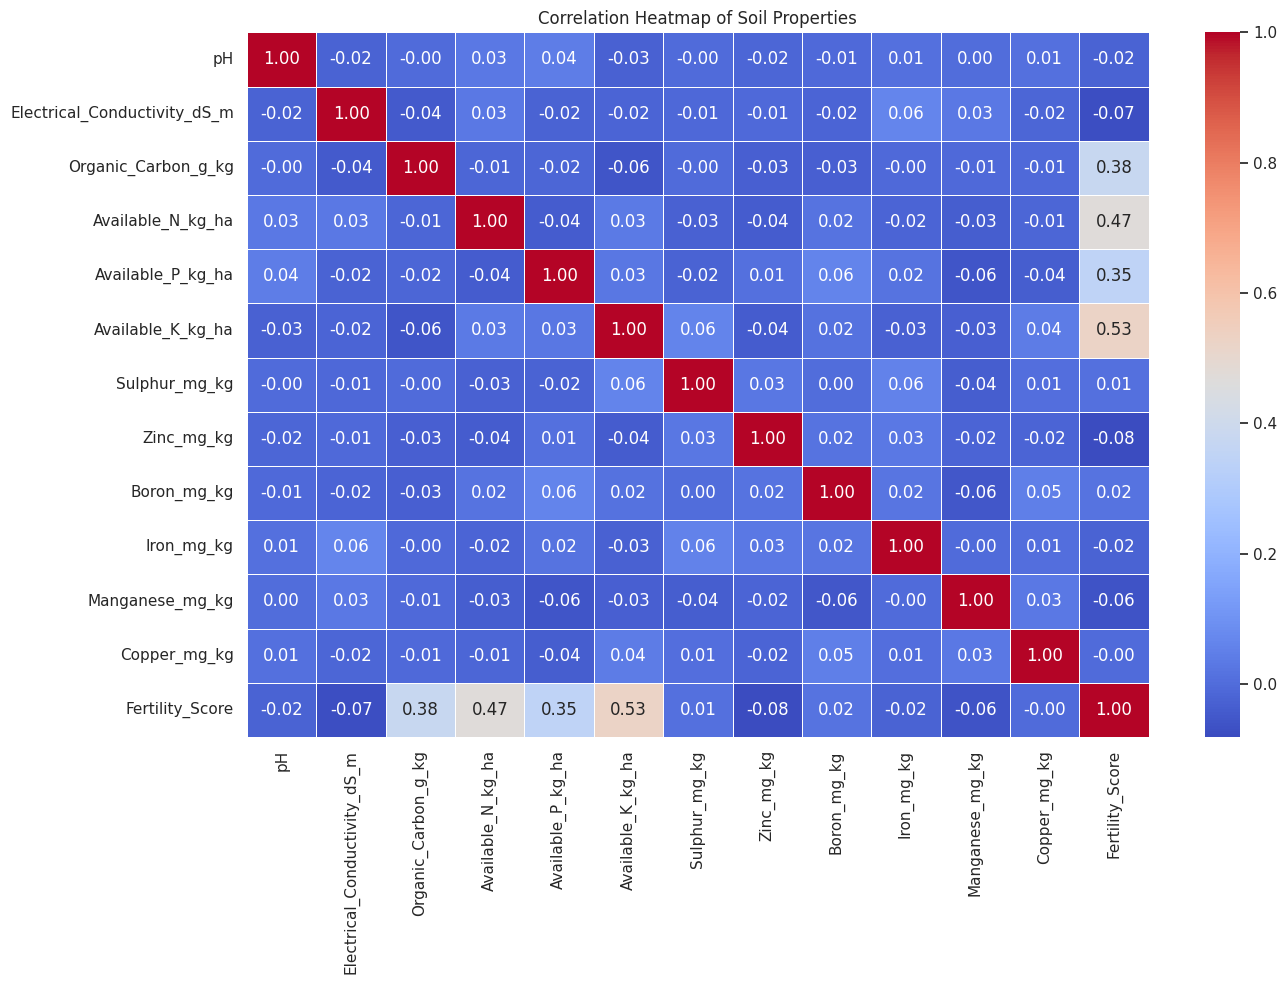

In [17]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Soil Properties")

plt.tight_layout()
plt.show()

In [18]:

columns_to_drop = [
    "Sample_ID",
    "Source_Calibration",
    "Fertility_Score",
    "Fertility_Class"
]


X = df.drop(columns=columns_to_drop)


y = df["Fertility_Class"]

print("Input Features:")
print(X.columns.tolist())

print("\nNumber of Features:", X.shape[1])

print("\nTarget Classes:")
print(y.unique())

Input Features:
['State', 'District', 'Soil_Type', 'Crop', 'pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg']

Number of Features: 16

Target Classes:
<StringArray>
['Medium Fertility', 'Low Fertility', 'High Fertility']
Length: 3, dtype: string


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 800
Testing Samples: 200

Training Class Distribution:
Fertility_Class
Medium Fertility    477
Low Fertility       255
High Fertility       68
Name: count, dtype: Int64

Testing Class Distribution:
Fertility_Class
Medium Fertility    119
Low Fertility        64
High Fertility       17
Name: count, dtype: Int64


In [20]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created!")

Numerical Features:
['pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg']

Categorical Features:
['State', 'District', 'Soil_Type', 'Crop']
Preprocessing pipeline created!


In [21]:
feature_selector = SelectKBest(
    score_func=f_classif,
    k="all"
)

print("Feature selection configured successfully!")

Feature selection configured successfully!


In [22]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

print("Four classification models initialized!")

for name in models:
    print(name)

Four classification models initialized!
Decision Tree
Random Forest
KNN
SVM


In [23]:
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

trained_models = {}
cv_results = []

for name, classifier in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("feature_selection", clone(feature_selector)),
            ("classifier", clone(classifier))
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        },
        n_jobs=-1
    )

    # Fit on the complete training set
    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="CV F1",
    ascending=False
)

display(cv_results_df.round(4))


Training Decision Tree...

Training Random Forest...

Training KNN...

Training SVM...


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std
3,SVM,0.8138,0.7871,0.7754,0.7748,0.0339
0,Decision Tree,0.7825,0.7349,0.7311,0.7292,0.0542
1,Random Forest,0.7813,0.7660,0.5527,0.5736,0.0379
2,KNN,0.6875,0.6288,0.5386,0.5605,0.0396


In [24]:
best_baseline_name = cv_results_df.iloc[0]["Model"]

print("Best Baseline Model:", best_baseline_name)

best_baseline = models[best_baseline_name]

Best Baseline Model: SVM


In [26]:
# Determine the number of transformed features
temporary_preprocessor = clone(preprocessor)

temporary_preprocessor.fit(X_train)

total_features = len(
    temporary_preprocessor.get_feature_names_out()
)

print("Total Transformed Features:", total_features)

# Candidate numbers of features
candidate_k = sorted(set([
    min(5, total_features),
    min(10, total_features),
    min(15, total_features),
    min(20, total_features),
    total_features
]))

feature_results = []

for k in candidate_k:

    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),

            (
                "feature_selection",
                SelectKBest(
                    score_func=f_classif,
                    k=k
                )
            ),

            (
                "classifier",
                clone(best_baseline)
            )
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    feature_results.append({
        "Number of Features": k,
        "Mean CV F1": scores["test_score"].mean()
    })

feature_results_df = pd.DataFrame(feature_results)

display(feature_results_df)

Total Transformed Features: 53


,Number of Features,Mean CV F1
0,5,0.801036
1,10,0.792511
2,15,0.809056
3,20,0.817628
4,53,0.774846


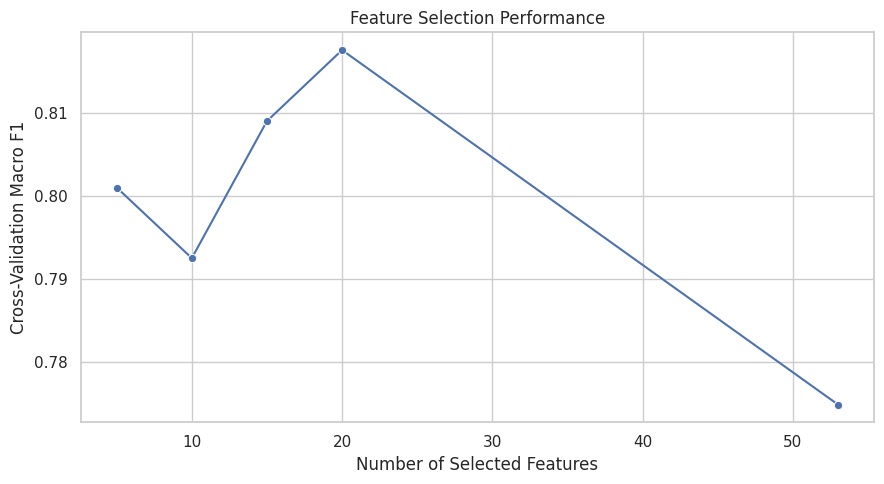

In [27]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=feature_results_df,
    x="Number of Features",
    y="Mean CV F1",
    marker="o"
)

plt.title("Feature Selection Performance")
plt.xlabel("Number of Selected Features")
plt.ylabel("Cross-Validation Macro F1")

plt.tight_layout()
plt.show()

In [28]:
best_k = int(
    feature_results_df.loc[
        feature_results_df["Mean CV F1"].idxmax(),
        "Number of Features"
    ]
)

print("Selected Number of Features:", best_k)

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),

        (
            "feature_selection",
            SelectKBest(
                score_func=f_classif,
                k=best_k
            )
        ),

        (
            "classifier",
            clone(models[best_baseline_name])
        )
    ]
)

param_grids = {
    "Decision Tree": {
        "classifier__max_depth": [3, 5, 10, None],
        "classifier__min_samples_split": [2, 5, 10]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [5, 10, None],
        "classifier__min_samples_leaf": [1, 2]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9],
        "classifier__weights": ["uniform", "distance"]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"],
        "classifier__kernel": ["rbf"]
    }
}

grid_search = GridSearchCV(
    estimator=final_pipeline,
    param_grid=param_grids[best_baseline_name],
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

print("Hyperparameter search configured!")

Selected Number of Features: 20
Hyperparameter search configured!


In [29]:
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

print("\nFinal Model:")
print(best_baseline_name)

Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}

Best Cross-Validation Macro F1:
0.8298

Final Model:
SVM


In [30]:
test_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    test_results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
3,SVM,0.845,0.8424,0.8315,0.8329
0,Decision Tree,0.835,0.8311,0.7827,0.8020
1,Random Forest,0.835,0.9168,0.6169,0.6430
2,KNN,0.690,0.6129,0.5645,0.5821


In [31]:
y_pred_final = best_model.predict(X_test)

final_accuracy = accuracy_score(
    y_test, y_pred_final
)

final_precision = precision_score(
    y_test,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_pred_final,
    average="macro",
    zero_division=0
)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")

print("Model:", best_baseline_name)
print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1-Score:", round(final_f1, 4))

FINAL MODEL PERFORMANCE
-----------------------
Model: SVM
Accuracy: 0.855
Precision: 0.8077
Recall: 0.8227
F1-Score: 0.8135


In [32]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_final,
        labels=order,
        zero_division=0
    )
)

Classification Report:
                  precision    recall  f1-score   support

   Low Fertility       0.81      0.92      0.86        64
Medium Fertility       0.91      0.84      0.87       119
  High Fertility       0.71      0.71      0.71        17

        accuracy                           0.85       200
       macro avg       0.81      0.82      0.81       200
    weighted avg       0.86      0.85      0.86       200



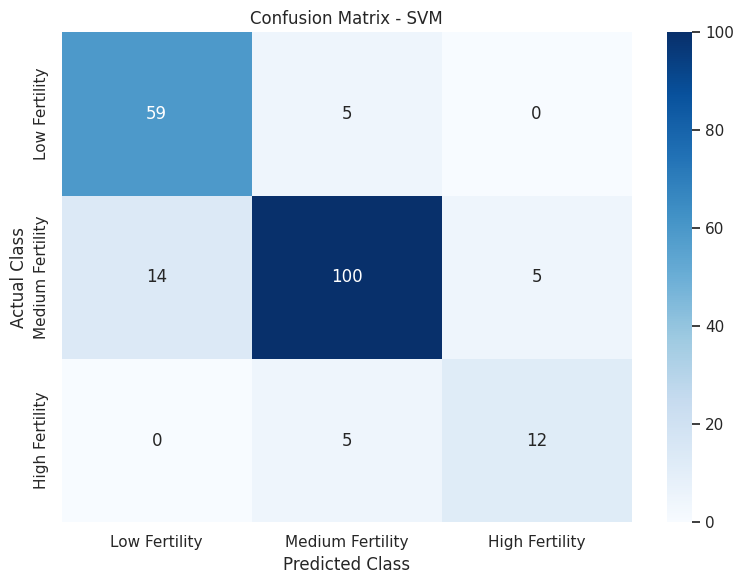

In [33]:
cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=order
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=order,
    yticklabels=order
)

plt.title(
    f"Confusion Matrix - {best_baseline_name}"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

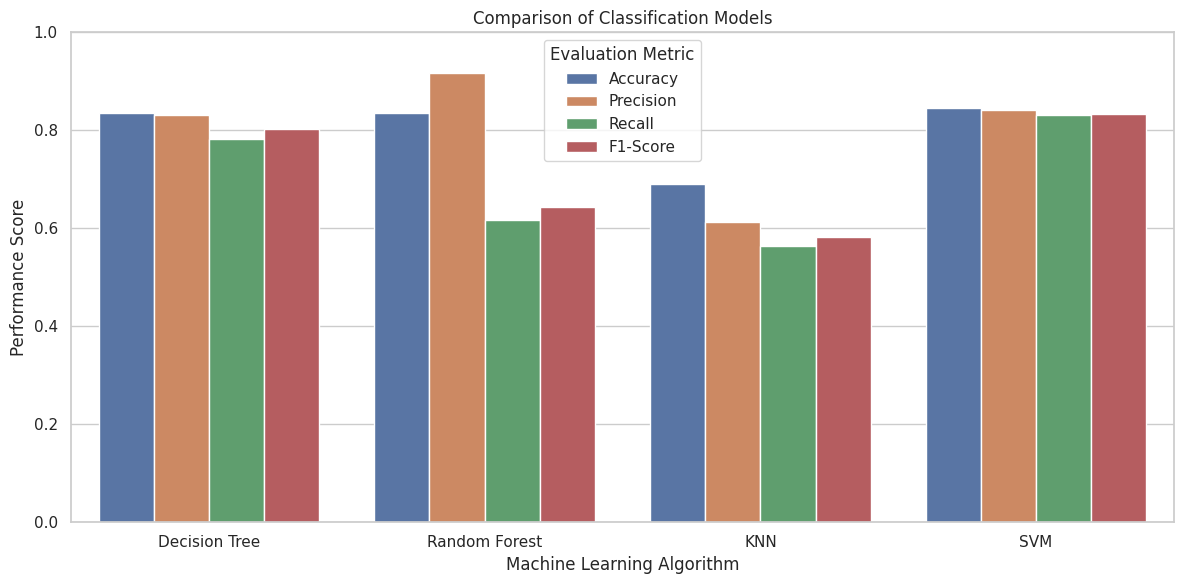

In [34]:
comparison_df = test_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Classification Models")

plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Performance Score")

plt.ylim(0, 1)
plt.legend(title="Evaluation Metric")

plt.tight_layout()
plt.show()

In [35]:
final_result = pd.DataFrame([{
    "Model": best_baseline_name + " (Tuned)",
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-Score": final_f1
}])

complete_results = pd.concat(
    [test_results_df, final_result],
    ignore_index=True
)

display(complete_results.round(4))

complete_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison saved!")

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.835,0.8311,0.7827,0.8020
1,Random Forest,0.835,0.9168,0.6169,0.6430
2,KNN,0.690,0.6129,0.5645,0.5821
3,SVM,0.845,0.8424,0.8315,0.8329
4,SVM (Tuned),0.855,0.8077,0.8227,0.8135


Model comparison saved!


In [36]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Results:")
display(importance_df)

Feature Importance Results:


,Feature,Importance,Std
9,Available_K_kg_ha,0.250694,0.026591
6,Organic_Carbon_g_kg,0.228056,0.035068
7,Available_N_kg_ha,0.185217,0.036310
8,Available_P_kg_ha,0.158019,0.031689
12,Boron_mg_kg,0.000000,0.000000
10,Sulphur_mg_kg,0.000000,0.000000
2,Soil_Type,0.000000,0.000000
14,Manganese_mg_kg,0.000000,0.000000
15,Copper_mg_kg,0.000000,0.000000
13,Iron_mg_kg,0.000000,0.000000


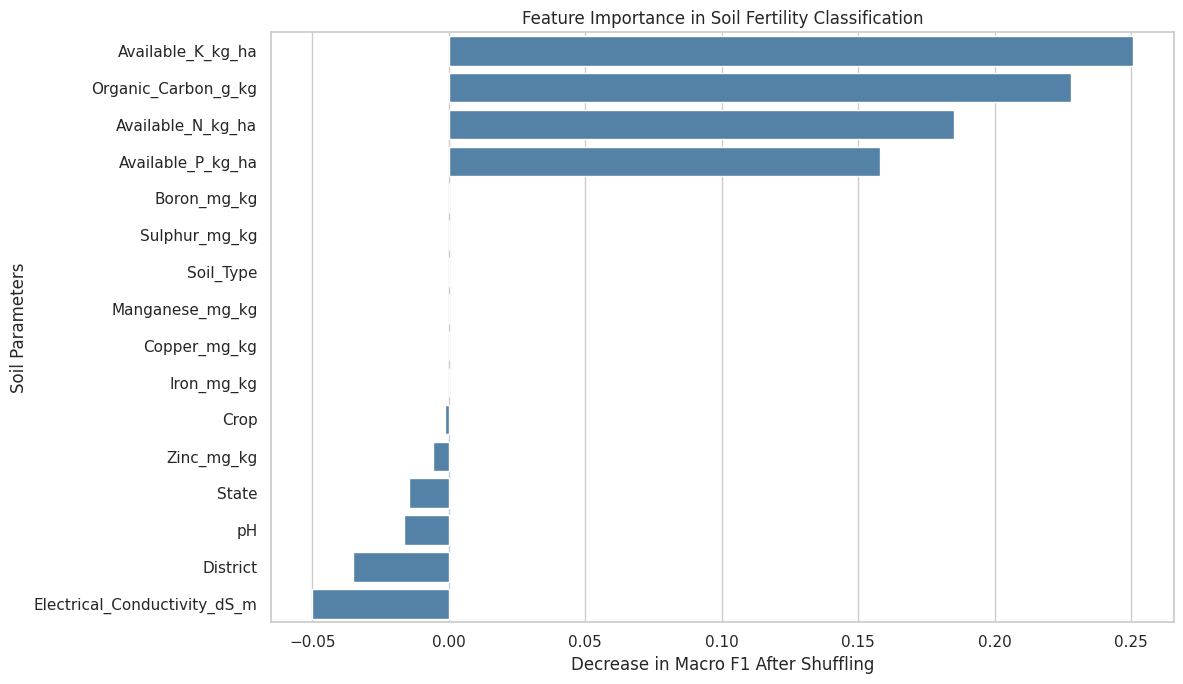

In [37]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Feature Importance in Soil Fertility Classification"
)

plt.xlabel("Decrease in Macro F1 After Shuffling")
plt.ylabel("Soil Parameters")

plt.tight_layout()
plt.show()

In [38]:
joblib.dump(
    best_model,
    "soil_fertility_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
from google.colab import files

files.download("soil_fertility_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
new_soil = pd.DataFrame([{
    "State": "West Bengal",
    "District": "Murshidabad",
    "Soil_Type": "Alluvial",
    "Crop": "Rice",

    "pH": 6.8,
    "Electrical_Conductivity_dS_m": 0.35,

    "Organic_Carbon_g_kg": 8.5,

    "Available_N_kg_ha": 280,
    "Available_P_kg_ha": 25,
    "Available_K_kg_ha": 240,

    "Sulphur_mg_kg": 12,
    "Zinc_mg_kg": 1.2,
    "Boron_mg_kg": 0.8,

    "Iron_mg_kg": 15,
    "Manganese_mg_kg": 6,
    "Copper_mg_kg": 1.1
}])

# Match the training feature order
new_soil = new_soil[X_train.columns]

print("New Soil Sample:")
display(new_soil)

New Soil Sample:


,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg
0,West Bengal,Murshidabad,Alluvial,Rice,6.8,0.35,8.5,280,25,240,12,1.2,0.8,15,6,1.1


In [41]:
prediction = best_model.predict(new_soil)

print("--------------------------------")
print("SOIL FERTILITY PREDICTION")
print("--------------------------------")

print("Predicted Fertility Class:", prediction[0])

--------------------------------
SOIL FERTILITY PREDICTION
--------------------------------
Predicted Fertility Class: High Fertility
